# LEGO brick crops and color IDs
**ECE 539 · Team G01 · Khang Lam (P3)**

Divij’s detector locates each brick. This stage cuts one 224 × 224 RGB image per bounding box. Isaiah’s classifier receives those crops to identify shapes. A fixed color matcher reads the same crops and returns a Rebrickable color ID for each one. Jay can join the two predictions by their detector row index.

**Run the example.** Extract the ZIP, open this notebook, and run all cells. The example uses two bundled photographs and manually drawn boxes so it runs on a CPU. Dependencies are NumPy, Pillow, pandas, matplotlib and Jupyter. In Colab, upload the ZIP to the Files panel and run `!unzip -o /content/Khang_crop_and_color.zip -d /content` in a cell first.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

locations = [Path.cwd(), Path.cwd() / "P3", Path("/content/P3")]
P3 = next((p.resolve() for p in locations if (p / "crop_and_color.py").is_file()), None)
if P3 is None:
    raise FileNotFoundError("Extract the ZIP and open this notebook in the P3 folder.")
sys.path.insert(0, str(P3))
from crop_and_color import DEFAULT_PALETTE, crop_bricks, match_colors

example_dir = P3 / "examples"
annotations = pd.read_csv(example_dir / "boxes.csv")
coords = ["x1", "y1", "x2", "y2"]

## From a detector row to a crop

The numbered rectangles stand in for detector output. Coordinates are original-image pixels, with the origin at the upper left. Each number is the zero-based row within that photo. The first photo shows six selected pieces inside a larger pile. The second shows all five pieces in a three-color scene.

In [2]:
scenes = list(annotations.groupby("image", sort=False))
fig, axes = plt.subplots(1, len(scenes), figsize=(12, 5), constrained_layout=True)
for ax, (filename, rows) in zip(axes, scenes):
    with Image.open(example_dir / filename) as photo:
        ax.imshow(photo.convert("RGB"))
    for i, (x1, y1, x2, y2) in enumerate(rows[coords].itertuples(index=False, name=None)):
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color="white", linewidth=1.5))
        ax.text(x1, y1, str(i), va="top", color="white", fontsize=10,
                bbox=dict(facecolor="#222222", edgecolor="none", pad=2))
    ax.set_title(filename)
    ax.axis("off")
plt.show()

<Figure size 1200x500 with 2 Axes>

## Match the median brick color

For each crop, take the per-channel median inside the central half of its width and height. This keeps much of the box-edge background out of the sample. Convert that median and the 24 fixed opaque palette swatches to CIELAB. Choose the swatch with the smallest Euclidean distance (ΔE76). A smaller distance means a closer swatch match. The distance is in color units and has no probability interpretation.

The outlines below show precisely which pixels contribute. The shape classifier receives the entire crop, including the region outside the outline.

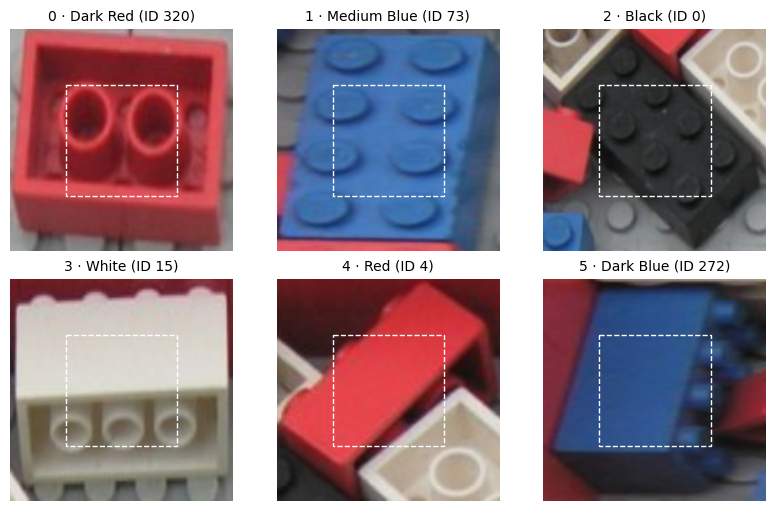

In [3]:
filename, rows = scenes[0]
with Image.open(example_dir / filename) as photo:
    crops = crop_bricks(photo, rows[coords].to_numpy())
matches = match_colors(crops)

fig, axes = plt.subplots(2, 3, figsize=(8, 5), constrained_layout=True)
for i, (ax, crop, match) in enumerate(zip(axes.flat, crops, matches)):
    ax.imshow(crop)
    ax.add_patch(Rectangle((56, 56), 112, 112, fill=False, color="white", linestyle="--"))
    ax.set_title(f"{i} · {match.color_name} (ID {match.color_id})", fontsize=10)
    ax.axis("off")
plt.show()

## Check color predictions against labels

Each CSV row is one brick with a reference color label. For these two public examples, the labels are apparent color names mapped to Rebrickable IDs. Exact manufacturer shades are unverified. In a team evaluation, use known physical color IDs and one row per brick on held-out phone photos. Point the function below to a CSV with the same columns and the directory containing those photos. Accuracy here is the fraction of labeled boxes with a matching color ID. Detector misses and part recognition require a separate end-to-end evaluation.

In [4]:
def evaluate_boxes(labels, image_dir, palette=None):
    records = []
    for filename, group in labels.groupby("image", sort=False):
        with Image.open(image_dir / filename) as photo:
            crops = crop_bricks(photo, group[coords].to_numpy())
        for i, (expected, match) in enumerate(zip(group.color_id, match_colors(crops, palette))):
            records.append({
                "image": filename, "box": i, "label_id": int(expected),
                "predicted_id": match.color_id, "predicted_name": match.color_name,
                "median_rgb": match.median_rgb, "delta_e": round(match.delta_e, 1),
                "correct": int(expected) == match.color_id,
            })
    return pd.DataFrame.from_records(records)

results = evaluate_boxes(annotations, example_dir)
display(results)
print(f"Default palette: {results.correct.sum()}/{len(results)} demo labels matched.")

,image,box,label_id,predicted_id,predicted_name,median_rgb,delta_e,correct
0,LEGO-02.jpg,0,4,320,Dark Red,"(141, 33, 39)",9.9,False
1,LEGO-02.jpg,1,1,73,Medium Blue,"(65, 114, 176)",13.4,False
2,LEGO-02.jpg,2,0,0,Black,"(46, 48, 49)",16.2,True
3,LEGO-02.jpg,3,15,15,White,"(213, 207, 198)",17.4,True
4,LEGO-02.jpg,4,4,4,Red,"(223, 67, 74)",24.2,True
5,LEGO-02.jpg,5,1,272,Dark Blue,"(46, 80, 137)",13.2,False
6,Old_duplo_bricks.jpg,0,1,72,Dark Bluish Gray,"(63, 87, 109)",21.2,False
7,Old_duplo_bricks.jpg,1,14,25,Orange,"(208, 124, 2)",16.0,False
8,Old_duplo_bricks.jpg,2,4,4,Red,"(205, 55, 21)",7.6,True
9,Old_duplo_bricks.jpg,3,1,73,Medium Blue,"(74, 132, 178)",16.2,False


Default palette: 5/11 demo labels matched.


The first blue brick viewed from above and the one viewed from the side received different blue shades. A brick photographed from underneath also includes deep shadows. A wide palette allows those small appearance changes to select a different catalog ID.

If a collection’s possible colors are known *in advance*, use that palette explicitly. The photographer describes only blue, red and yellow pieces in the second scene. This rerun demonstrates that narrower task on the same pixels.

In [5]:
known_scene = annotations.loc[annotations.image == "Old_duplo_bricks.jpg"]
known_palette = {i: DEFAULT_PALETTE[i] for i in (1, 4, 14)}
restricted = evaluate_boxes(known_scene, example_dir, known_palette)
display(restricted[["box", "label_id", "predicted_id", "predicted_name", "correct"]])
print(f"Three-color scene: {restricted.correct.sum()}/{len(restricted)} broad color labels matched.")

,box,label_id,predicted_id,predicted_name,correct
0,0,1,1,Blue,True
1,1,14,14,Yellow,True
2,2,4,4,Red,True
3,3,1,1,Blue,True
4,4,14,14,Yellow,True


Three-color scene: 5/5 broad color labels matched.


## Connect Divij, Isaiah and Jay

Call the function below with one Ultralytics detection result and Isaiah’s trained classifier. It uses the exact source pixels paired with the YOLO result. Ultralytics stores that image in BGR order, so the function reverses its channels once. Isaiah’s `classifier.predict` performs tensor conversion and ImageNet normalization internally.

The function returns one row per detection. The coordinates remain in original-image pixels, and the color ID is an integer. Jay can use those rows for counts and overlays.

In [ ]:
def label_detections(result, shape_model, classes, device="cpu", palette=None):
    # P3 and P2 are siblings in the team repository.
    from P2 import classifier

    photo = Image.fromarray(result.orig_img[:, :, ::-1].copy())
    xyxy = result.boxes.xyxy.detach().cpu().numpy()
    crops = crop_bricks(photo, xyxy)
    colors = match_colors(crops, palette)
    part_ids, part_scores, _ = classifier.predict(shape_model, crops, classes, device=device)
    output = pd.DataFrame(xyxy, columns=coords)
    output.insert(0, "detection_index", np.arange(len(crops), dtype=int))
    output["part_id"] = part_ids
    output["part_confidence"] = part_scores
    output["color_id"] = pd.Series([m.color_id for m in colors], dtype="int64")
    return output

#
# from P2 import classifier
# from ultralytics import YOLO
# classes = classifier.load_classes(P3.parent / "P2" / "classes_50.csv")
# shape_model = classifier.load_model("path/to/shape/best.pt", device="cpu")
# result = YOLO("path/to/brick_detector/best.pt")("my_photo.jpg", verbose=False)[0]
# label_detections(result, shape_model, classes)

### Example data

- Six hand-drawn boxes in *LEGO-02.jpg*, photographed by Priwo and released into the public domain. [Photograph and attribution](https://commons.wikimedia.org/wiki/File:LEGO-02.jpg)
- Five hand-drawn boxes in *Old duplo bricks.jpg*, photographed by Klas Schöldström and released into the public domain. [Photograph and color description](https://commons.wikimedia.org/wiki/File:Old_duplo_bricks.jpg)
- Reference swatches are a fixed subset of the Rebrickable colors table. To use another palette, pass `palette=load_palette("my_colors.csv")` after importing `load_palette` from `crop_and_color`. The CSV uses `id,name,rgb` columns, with six-digit hexadecimal RGB values. [Rebrickable downloads](https://rebrickable.com/downloads/)